# Supervised Learning & Model Engineering - Group project
# STEP 3: Baseline model, evaluation module, experiment tracking

**Dataset:** Adult / Census Income (OpenML, `name="adult"`, `version=2`)
**Group:** Clément, Eliott Monneraie, Lucas Stefani (done together by the three members, reviewed by all)
**Course reference:** Session 1 (logistic regression, log-loss, 5-fold StratifiedKFold), Session 2 (regularization, scaling), Session 6 (confusion matrix, precision, recall, ROC-AUC vs PR-AUC)
**Code:** `src/evaluate.py` (metrics + cross-validation), `src/models.py` (baseline Pipeline), `src/tracking.py` (MLflow). This notebook calls the code, shows the results and explains them.

### How to read this notebook
Same labels as STEPS 1 and 2: **What we see**, **What we decide**, **What could invalidate it**, **Note for STEP X**, **Limitation**.

### The rule of this step
Development set only, 5-fold StratifiedKFold from STEP 1. The test set is not touched: it is used once, in STEP 6.

### How to run
From the project root, after `python -m src.data`. In Colab: first clone the repository (see the README). Runtime: about one minute.

In [1]:
# ===================== Setup =====================
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_recall_curve, roc_curve

# Run from the project root (works from notebooks/ too), so that src/ and config.yaml are found.
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
from src.data import load_config, load_splits, get_cv
from src.models import build_logistic
from src.evaluate import cross_validate_oof, compute_metrics, summarize, format_summary, METRIC_NAMES
from src.tracking import setup_mlflow, log_cv_run

warnings.filterwarnings("ignore")
cfg = load_config()
FIG_DIR = cfg["paths"]["figures_dir"]
os.makedirs(FIG_DIR, exist_ok=True)
sns.set_theme(style="whitegrid")

def savefig(name: str) -> str:
    path = os.path.join(FIG_DIR, f"{name}.png")
    plt.tight_layout(); plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved: {path}")
    return path

X_dev, _, y_dev, _ = load_splits(cfg)          # the test set is not used in STEP 3
cv = get_cv(cfg)
prevalence = y_dev.mean()
THRESHOLD = cfg["evaluation"]["default_threshold"]
print(f"Development set: {len(y_dev)} rows, prevalence = {prevalence:.2%}")

Development set: 39032 rows, prevalence = 23.94%


---
# Part A - What we measure, and why (Sessions 1 and 6)

The model outputs a probability $\hat p(x) = P(Y=1 \mid x)$. Some metrics judge these probabilities directly; others judge the decision obtained with a threshold $t$: $\hat y = \mathbb{1}\{\hat p(x) \ge t\}$.

| Metric | Question it answers | Depends on the threshold? | Course |
|---|---|---|---|
| **PR-AUC** (average precision) | Over all thresholds, how well do we rank the >50K people at the top, measured with precision and recall? Random ranking = prevalence (23.9%). | No | S6 |
| **ROC-AUC** | Probability that a random >50K person gets a higher score than a random <=50K person. Random = 0.5. | No | S6 |
| **Log-loss** | How good are the probabilities themselves? It is the loss that trains logistic regression. Lower is better. | No | S1 |
| **Precision** $= \frac{TP}{TP+FP}$ | Of the prospects we contact, what share really earn >50K? (useful calls) | Yes | S6 |
| **Recall** $= \frac{TP}{TP+FN}$ | Of all the >50K prospects, what share do we contact? (wealthy clients found) | Yes | S6 |
| **F1** | Harmonic compromise between precision and recall | Yes | S6 |
| **Confusion matrix** | TP, FP, FN, TN: the four kinds of outcome, in counts | Yes | S6 |

**What we decide.**
- **PR-AUC is our main metric.** The positive class is the minority (23.9%) and it is the one the bank cares about. Session 6 warns that ROC-AUC can look strong while precision on the rare class is poor, because many false positives still give a small false positive rate. We still report ROC-AUC as a secondary metric.
- **The threshold-dependent metrics are reported at $t = 0.5$ only as a reference.** There is no universally correct threshold (Session 6). Choosing the operating threshold is part of STEP 4 (class imbalance) and is done on out-of-fold predictions, never on the test set.
- **Every model of the project is evaluated with the same function** (`src/evaluate.py`) on the same 5 folds, so that comparisons in STEP 6 are fair.

**How the cross-validation works in our code.** For each of the 5 folds, a fresh copy of the **whole Pipeline** (STEP 2 preprocessing + model) is fitted on the 4 training folds and predicts the 5th. We keep these **out-of-fold (OOF) predictions**: every development row gets a probability from a model that never saw it. STEP 4 (threshold) and STEP 7 (calibration) are built on them.

---
# Part B - The baseline: L2-regularized logistic regression

**Why logistic regression first.** It is the course's reference model for binary classification (Session 1): it models $P(Y=1 \mid x) = \sigma(x^\top \beta)$, it is trained by minimizing log-loss, and its coefficients can be read. Every more complex model (STEP 5) has to beat it to justify its complexity.

**Why L2 (Ridge) regularization** (Session 2). Several of our inputs are correlated (`marital-status` and `relationship` both describe the household; `age` and `age_band`). Without a penalty, correlated predictors give unstable coefficients. The L2 penalty shrinks coefficients and keeps them stable, without setting them to zero (Lasso would). In scikit-learn the strength is set by $C = 1/\lambda$: a smaller $C$ means a stronger penalty.

**Why $C = 1$ for now.** It is scikit-learn's default. Session 2: *"The correct strength is a model-selection question."* We answer it with Optuna and cross-validation in STEP 5. STEP 3 only sets the reference point.

**Scaling.** Session 2: regularization penalizes coefficient sizes, which depend on units, so features must be standardized, with the scaler fitted on training data only. That is already inside our Pipeline (STEP 2, `StandardScaler` for the linear family).

```
raw row -> AdultFeatureBuilder -> ColumnTransformer (impute, one-hot, scale) -> LogisticRegression(penalty="l2", C=1)
           \___________________ STEP 2: build_preprocessor(cfg, "linear") ___________________/   \____ STEP 3 ____/
```

In [2]:
# ===================== B.1 5-fold cross-validation of the baseline =====================
pipe = build_logistic(cfg)
per_fold, oof = cross_validate_oof(pipe, X_dev, y_dev, cv, threshold=THRESHOLD)

print("Per fold:")
display(per_fold[METRIC_NAMES + ["tp", "fp", "fn", "tn"]].round(3))
print("Mean +/- standard deviation over the 5 folds:")
summary = summarize(per_fold)
display(summary.style.format("{:.3f}"))
print(f"PR-AUC of a random ranking (prevalence): {prevalence:.3f}")

Per fold:


,pr_auc,roc_auc,log_loss,precision,recall,f1,tp,fp,fn,tn
fold,,,,,,,,,,
1,0.740,0.897,0.333,0.713,0.581,0.640,1086,438,783,5500
2,0.737,0.896,0.334,0.710,0.576,0.636,1076,440,793,5498
3,0.748,0.903,0.326,0.734,0.607,0.664,1134,411,735,5526
4,0.736,0.900,0.330,0.720,0.590,0.649,1103,428,766,5509
5,0.764,0.909,0.317,0.742,0.621,0.676,1161,403,708,5534


Mean +/- standard deviation over the 5 folds:


,mean,std
pr_auc,0.745,0.012
roc_auc,0.901,0.005
log_loss,0.328,0.007
precision,0.724,0.014
recall,0.595,0.019
f1,0.653,0.017


PR-AUC of a random ranking (prevalence): 0.239


**What we see.**
- **PR-AUC = 0.745 ± 0.012**, about **3.1 times the random baseline** (0.239). Same number as the STEP 2 feature check, which confirms that the STEP 2 Pipeline and the STEP 3 code agree.
- **ROC-AUC = 0.901 ± 0.005.** High, but as Session 6 warns, it looks better than PR-AUC because the many easy <=50K people inflate it.
- **Log-loss = 0.328.** A model that always predicted the prevalence (23.9%) would have a log-loss of about 0.55, so the probabilities carry real information.
- **At $t = 0.5$: precision 0.724, recall 0.595, F1 0.653.** The model is cautious: when it says ">50K" it is right 72% of the time, but it finds only 60% of the >50K people.
- **The standard deviation across folds is small** (0.012 for PR-AUC): the score does not depend much on which rows are in the validation fold. Differences between models smaller than about 0.01 to 0.02 will not be meaningful (STEP 6).

Figure saved: reports/figures/12_baseline_pr_roc_confusion.png


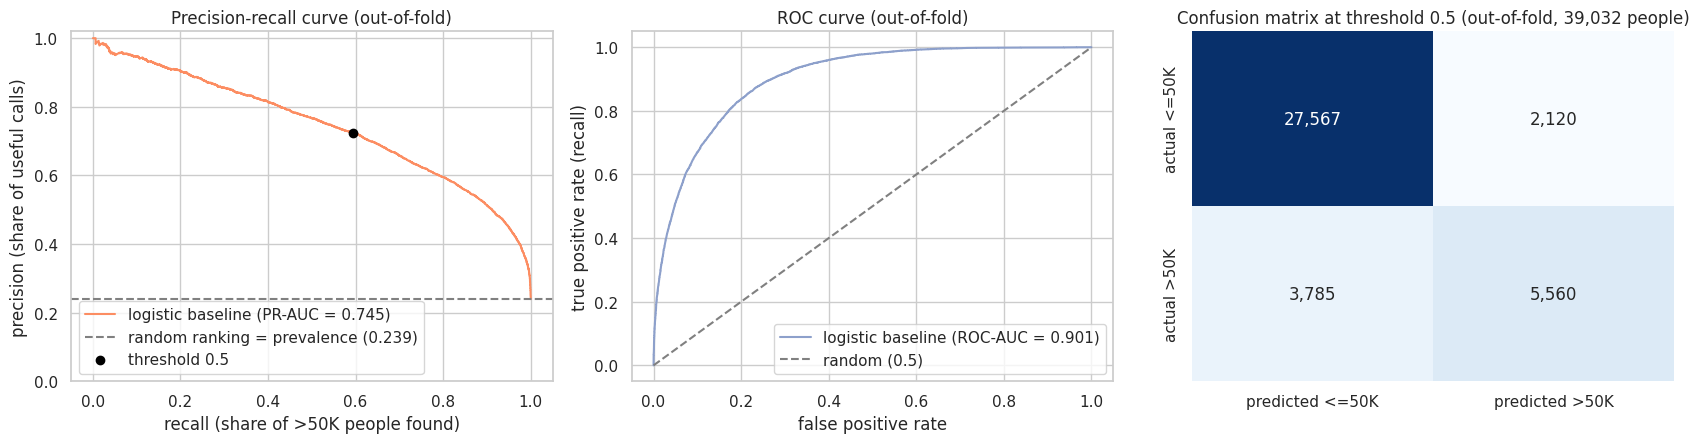

Prospects contacted at t = 0.5: 7,680 (19.7% of the development set)
  useful calls (TP)            : 5,560
  useless calls (FP)           : 2,120
  >50K prospects missed (FN)   : 3,785 of 9,345


In [3]:
# ===================== B.2 Curves and confusion matrix on the out-of-fold predictions =====================
pooled = compute_metrics(y_dev, oof, THRESHOLD)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

prec, rec, _ = precision_recall_curve(y_dev, oof)
axes[0].plot(rec, prec, color="#fc8d62", label=f"logistic baseline (PR-AUC = {pooled['pr_auc']:.3f})")
axes[0].axhline(prevalence, ls="--", color="grey", label=f"random ranking = prevalence ({prevalence:.3f})")
axes[0].scatter(pooled["recall"], pooled["precision"], color="black", zorder=3, label=f"threshold {THRESHOLD}")
axes[0].set(xlabel="recall (share of >50K people found)", ylabel="precision (share of useful calls)",
            title="Precision-recall curve (out-of-fold)", ylim=(0, 1.02)); axes[0].legend(loc="lower left")

fpr, tpr, _ = roc_curve(y_dev, oof)
axes[1].plot(fpr, tpr, color="#8da0cb", label=f"logistic baseline (ROC-AUC = {pooled['roc_auc']:.3f})")
axes[1].plot([0, 1], [0, 1], ls="--", color="grey", label="random (0.5)")
axes[1].set(xlabel="false positive rate", ylabel="true positive rate (recall)", title="ROC curve (out-of-fold)")
axes[1].legend(loc="lower right")

cm = np.array([[pooled["tn"], pooled["fp"]], [pooled["fn"], pooled["tp"]]])
sns.heatmap(cm, annot=True, fmt=",", cmap="Blues", cbar=False, ax=axes[2],
            xticklabels=["predicted <=50K", "predicted >50K"], yticklabels=["actual <=50K", "actual >50K"])
axes[2].set_title(f"Confusion matrix at threshold {THRESHOLD} (out-of-fold, {len(y_dev):,} people)")
fig_curves = savefig("12_baseline_pr_roc_confusion")
plt.show()

contacted = pooled["tp"] + pooled["fp"]
print(f"Prospects contacted at t = {THRESHOLD}: {contacted:,} ({contacted / len(y_dev):.1%} of the development set)")
print(f"  useful calls (TP)            : {pooled['tp']:,}")
print(f"  useless calls (FP)           : {pooled['fp']:,}")
print(f"  >50K prospects missed (FN)   : {pooled['fn']:,} of {pooled['tp'] + pooled['fn']:,}")

**What we see in the precision-recall curve.** The curve stays far above the dashed line (random ranking at 23.9%). On the left, the people the model is most sure about: precision close to 1. As we contact more people (moving right), recall rises and precision falls. The black dot is the operating point at $t = 0.5$: recall 0.60, precision 0.72.

**What we see in the ROC curve.** It hugs the top-left corner (0.901). The comparison with the PR curve illustrates Session 6: the same model looks "excellent" in ROC and "good" in PR, because ROC uses the false positive rate, which stays small even with a few thousand false positives among 29,700 negatives.

**What the confusion matrix means for the bank** (development set, each person predicted by a model that never saw them). At $t = 0.5$ the bank would contact **7,680 prospects (19.7%)**:
- **5,560 useful calls** (true positives);
- **2,120 useless calls** (false positives);
- **3,785 wealthy prospects never contacted** (false negatives), i.e. **40% of the >50K people missed**.

**What we decide: the business priority is recall.** For a private bank, a useless call costs a few minutes of an advisor's time, while a wealthy prospect never contacted is a client (and the fees on their assets) lost to a competitor. So **a false negative costs more than a false positive**: we would rather call some people who turn out not to be wealthy than miss wealthy ones (STEP 1, A.3). With 40% of the >50K prospects missed, the threshold 0.5 is too high for this business. Lowering it finds more wealthy prospects at the cost of more useless calls; STEP 4 chooses where to stop.

**What could invalidate it.** If advisor capacity were very limited (for example a fixed number of calls per week), precision would matter more and the threshold would be set by that capacity instead.

**Note for STEP 4.** Session 6 remedy hierarchy, compared on the same folds: (1) threshold tuning on these out-of-fold predictions, (2) class weights, (3) SMOTE. The PR-AUC 0.745 will not change with the threshold (Session 6: threshold tuning changes the operating point, not the ranking); precision, recall and F1 will.

Figure saved: reports/figures/13_baseline_coefficients.png


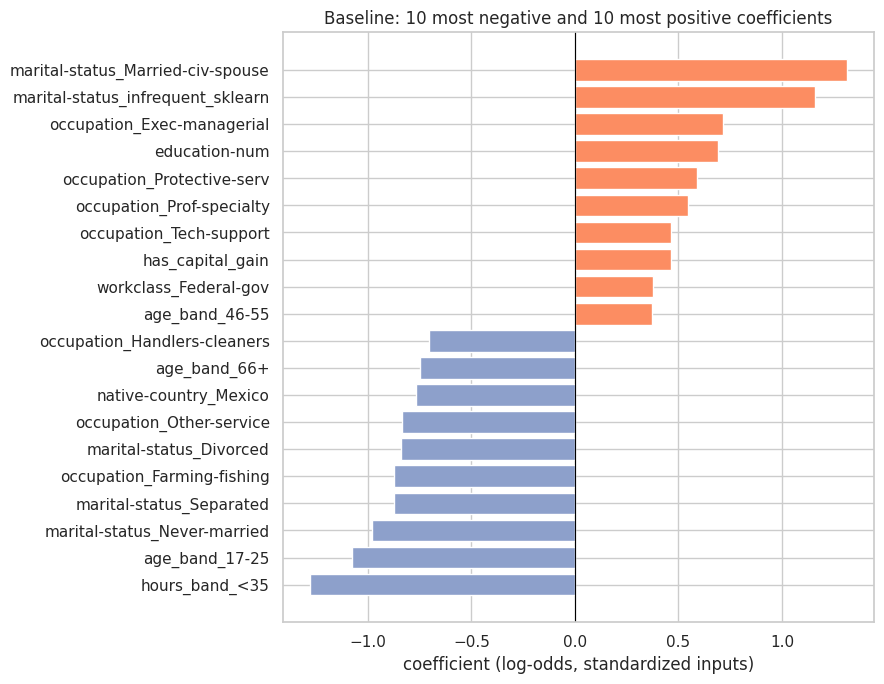

54 model inputs after preprocessing


In [4]:
# ===================== B.3 What the baseline learned: coefficients =====================
# Session 1: once the modelling choice is fixed, refit on the complete development set.
final_dev = build_logistic(cfg).fit(X_dev, y_dev)
names = final_dev.named_steps["preprocess"].get_feature_names_out()
coefs = pd.Series(final_dev.named_steps["model"].coef_[0], index=names).sort_values()
top = pd.concat([coefs.head(10), coefs.tail(10)])

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top.index, top.values, color=np.where(top.values > 0, "#fc8d62", "#8da0cb"))
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="coefficient (log-odds, standardized inputs)", title="Baseline: 10 most negative and 10 most positive coefficients")
fig_coefs = savefig("13_baseline_coefficients")
plt.show()
print(f"{len(names)} model inputs after preprocessing")

**How to read a coefficient.** It is the change in the **log-odds** of earning >50K when the input increases by one unit, all other inputs fixed. Numeric inputs are standardized, so "one unit" means one standard deviation. A one-hot column compares that category with the other categories of the same variable.

**What we see.**
- **Positive:** being married (`Married-civ-spouse`), `education-num`, executive and professional occupations (`Exec-managerial`, `Prof-specialty`), having a capital gain (`has_capital_gain`).
- **Negative:** working part-time (`hours_band_<35`), being 17-25 (`age_band_17-25`), never married, divorced or separated, low-paid occupations (`Other-service`, `Farming-fishing`).
- These directions match the STEP 1 EDA and make business sense.
- **The age bands reproduce the bell curve of STEP 1:** `age_band_46-55` is positive while `age_band_17-25` and `age_band_66+` are negative. A single coefficient on `age` could not do that; this is the effect of the bands added in STEP 2.
- **`marital-status_infrequent_sklearn`** has a large coefficient. It groups the rare categories (essentially `Married-AF-spouse`, 37 people), so its coefficient is estimated on very few people. It illustrates why we grouped rare categories (STEP 2) and why Session 2 warns against reading one coefficient alone.

**Limitation.** Coefficients describe associations learned by this model, not causes (Session 8 will make the same point for SHAP). With correlated inputs (married / spouse, age / age band), the L2 penalty shares the weight between them, so one coefficient should not be interpreted in isolation.

---
# Part C - Experiment tracking with MLflow (requirement 7)

**What MLflow is.** A logbook for experiments. For every training run it records:
- the **parameters** (the settings: model, `C`, penalty, preprocessing options, threshold, number of folds, seed);
- the **metrics** (mean and standard deviation over the 5 folds, and the value of each fold);
- the **artifacts** (files: the per-fold table, the figures).

Runs are stored in the local folder `mlruns/` (not committed: it can become large). The command `mlflow ui` opens a web page that lists all runs in a table, to sort and compare them.

**Why we need it.** In STEP 5, Optuna will train dozens of versions of each model. Requirement 7 asks to log every one of them. One run = one trained and cross-validated configuration.

In [5]:
# ===================== C.1 Log the baseline as one MLflow run =====================
setup_mlflow(cfg)
params = {**{f"model_{k}": v for k, v in cfg["models"]["logistic"].items()},
          "capital": cfg["features"]["capital"], "bands": ",".join(cfg["features"]["bands"]),
          "threshold": THRESHOLD, "n_folds": cfg["split"]["n_folds"], "seed": cfg["seed"]}
run_id = log_cv_run("step3_logistic_baseline", params, per_fold,
                    tags={"step": "3", "model": "logistic_regression", "family": "linear"},
                    figures=[fig_curves, fig_coefs])

import mlflow
runs = mlflow.search_runs(experiment_names=[cfg["tracking"]["experiment_name"]])
cols = ["tags.mlflow.runName", "params.model_C", "params.model_penalty",
        "metrics.cv_pr_auc_mean", "metrics.cv_pr_auc_std", "metrics.cv_roc_auc_mean", "metrics.cv_log_loss_mean"]
display(runs[cols].round(4))

2026/10/16 15:24:07 INFO mlflow.tracking.fluent: Experiment with name 'adult-income' does not exist. Creating a new experiment.


,tags.mlflow.runName,params.model_C,params.model_penalty,metrics.cv_pr_auc_mean,metrics.cv_pr_auc_std,metrics.cv_roc_auc_mean,metrics.cv_log_loss_mean
0,step3_logistic_baseline,1.0,l2,0.7449,0.0117,0.9011,0.3281


**What we see.** The table above is what MLflow stores: one line per run, with its parameters and metrics. It is the same table the `mlflow ui` page shows, and the one we will screenshot for the report once STEP 5 has filled it with the tuning trials.

---
# Part D - Decisions log for STEP 3 (copied into DECISIONS.md)

| # | Decision | Why | What could invalidate it | Where |
|---|---|---|---|---|
| 20 | One evaluation function for every model: PR-AUC (main, random baseline = prevalence), ROC-AUC, log-loss, precision, recall, F1, confusion matrix | Same metrics, same folds, fair comparison (requirement 4); PR-AUC suits a 23.9% minority class (S6) | - | `src/evaluate.py` |
| 21 | Threshold-dependent metrics reported at 0.5 only as a reference | No universal threshold (S6); the operating threshold is chosen in STEP 4 on out-of-fold predictions | - | `config.yaml` (`evaluation`) |
| 22 | Cross-validation keeps out-of-fold predictions; the full Pipeline is refitted on each training fold | No leakage from the validation fold; OOF predictions needed for STEP 4 (threshold) and STEP 7 (calibration) | - | `cross_validate_oof` |
| 23 | Baseline = logistic regression, L2 penalty, C = 1 (default), scaled inputs | Course reference model (S1); L2 keeps correlated coefficients stable (S2); C chosen in STEP 5 | - | `src/models.py`, `config.yaml` (`models`) |
| 24 | Baseline result (5-fold CV, development set): PR-AUC 0.745 ± 0.012, ROC-AUC 0.901 ± 0.005, log-loss 0.328; at t = 0.5 precision 0.724, recall 0.595, F1 0.653 | Reference every later model must beat | - | notebook 03 |
| 25 | MLflow logs every run (parameters, per-fold and summary metrics, artifacts) in the local `mlruns/` folder | Requirement 7; needed for the Optuna trials of STEP 5 | Session 10 using another tool | `src/tracking.py` |
| 26 | Business priority = recall: a missed wealthy prospect (FN) costs more than a useless call (FP), so the operating threshold will favour recall over precision | Lost client and fees vs a few minutes of advisor time (STEP 1, A.3); the baseline at 0.5 misses 40% of the >50K prospects | Fixed advisor capacity (then precision / number of calls drives the threshold) | STEP 4 (threshold choice) |

**Notes for STEP 4.** At t = 0.5 the baseline misses 40% of the >50K prospects (3,785 of 9,345). Following decision 26, the threshold is chosen on OOF predictions with an explicit business cost where a false negative costs more than a false positive (Session 6: "business cost of FP and FN under a chosen operating policy"); the cost ratio is set and justified in STEP 4. Compare on the same folds: threshold tuning on OOF predictions, then `class_weight="balanced"`, then SMOTE inside an `imblearn` Pipeline (training folds only). PR-AUC is not expected to change with the threshold; precision, recall and F1 will.